In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib
import seaborn as sns
import sklearn

print("Python:", sys.executable)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("Scikit-learn:", sklearn.__version__)

Python: d:\Portofolio\cardiovascular-ml-practicum\.venv\Scripts\python.exe
Pandas: 3.1.0
NumPy: 2.4.6
Matplotlib: 3.11.2
Seaborn: 0.13.2
Scikit-learn: 1.9.1


In [2]:
# Membaca dataset
df = pd.read_csv("../data/raw/cardio_train.csv", sep=";")

# Melihat ukuran dataset
print("Ukuran dataset:", df.shape)

# Menampilkan 5 baris pertama
df.head()

Ukuran dataset: (70000, 13)


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


In [3]:
# Melihat informasi struktur dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


In [4]:
# Melihat statistik deskriptif dataset
df.describe()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
count,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000
mean,49972.419900,19468.865814,1.349571,164.359229,74.205690,128.817286,96.630414,1.366871,1.226457,0.088129,0.053771,0.803729,0.499700
std,28851.302323,2467.251667,0.476838,8.210126,14.395757,154.011419,188.472530,0.680250,0.572270,0.283484,0.225568,0.397179,0.500003
min,0.000000,10798.000000,1.000000,55.000000,10.000000,-150.000000,-70.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,25006.750000,17664.000000,1.000000,159.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
50%,50001.500000,19703.000000,1.000000,165.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
75%,74889.250000,21327.000000,2.000000,170.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000
max,99999.000000,23713.000000,2.000000,250.000000,200.000000,16020.000000,11000.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000


In [5]:
# Menghitung jumlah setiap kelas cardio
df["cardio"].value_counts()

cardio
0    35021
1    34979
Name: count, dtype: int64

In [6]:
# Menghitung jumlah baris yang duplikat
df.duplicated().sum()

np.int64(0)

In [7]:
# Melihat statistik tekanan darah secara lebih detail
df[["ap_hi", "ap_lo"]].describe()

,ap_hi,ap_lo
count,70000.000000,70000.000000
mean,128.817286,96.630414
std,154.011419,188.472530
min,-150.000000,-70.000000
25%,120.000000,80.000000
50%,120.000000,80.000000
75%,140.000000,90.000000
max,16020.000000,11000.000000


In [8]:
# Menghitung jumlah nilai tekanan darah yang tidak wajar
print("ap_hi <= 0:", (df["ap_hi"] <= 0).sum())
print("ap_hi > 250:", (df["ap_hi"] > 250).sum())

print("ap_lo <= 0:", (df["ap_lo"] <= 0).sum())
print("ap_lo > 200:", (df["ap_lo"] > 200).sum())

ap_hi <= 0: 7
ap_hi > 250: 40
ap_lo <= 0: 22
ap_lo > 200: 953


In [9]:
# Menghitung baris dengan tekanan sistolik <= diastolik
(df["ap_hi"] <= df["ap_lo"]).sum()

np.int64(1236)

In [10]:
# Menggabungkan seluruh kondisi tekanan darah yang tidak wajar
invalid_bp = (
    (df["ap_hi"] <= 0) |
    (df["ap_hi"] > 250) |
    (df["ap_lo"] <= 0) |
    (df["ap_lo"] > 200) |
    (df["ap_hi"] <= df["ap_lo"])
)

# Menghitung jumlah baris yang memenuhi minimal satu kondisi
print("Jumlah baris bermasalah:", invalid_bp.sum())

# Menghitung persentasenya
print("Persentase:", round(invalid_bp.mean() * 100, 2), "%")

Jumlah baris bermasalah: 1291
Persentase: 1.84 %


In [11]:
# Menampilkan 10 contoh data dengan tekanan darah bermasalah
df.loc[
    invalid_bp,
    ["age", "gender", "height", "weight", "ap_hi", "ap_lo", "cardio"]
].head(10)

,age,gender,height,weight,ap_hi,ap_lo,cardio
228,17489,2,183,98.0,160,1100,1
241,21932,2,157,60.0,160,1000,1
260,18217,1,150,83.0,140,800,1
329,23407,1,176,63.0,160,1000,1
345,18704,1,154,81.0,140,1000,1
473,15226,1,150,95.0,150,1033,1
474,19099,1,156,65.0,120,150,0
559,20430,2,173,101.0,200,1000,1
567,21281,1,168,78.0,14,90,1
613,18963,1,165,92.0,140,1000,1


In [12]:
# Menampilkan contoh data bermasalah dengan index sebagai kolom
display(
    df.loc[
        invalid_bp,
        ["age", "gender", "height", "weight", "ap_hi", "ap_lo", "cardio"]
    ]
    .head(10)
    .reset_index(names="row_index")
)

,row_index,age,gender,height,weight,ap_hi,ap_lo,cardio
0,228,17489,2,183,98.0,160,1100,1
1,241,21932,2,157,60.0,160,1000,1
2,260,18217,1,150,83.0,140,800,1
3,329,23407,1,176,63.0,160,1000,1
4,345,18704,1,154,81.0,140,1000,1
5,473,15226,1,150,95.0,150,1033,1
6,474,19099,1,156,65.0,120,150,0
7,559,20430,2,173,101.0,200,1000,1
8,567,21281,1,168,78.0,14,90,1
9,613,18963,1,165,92.0,140,1000,1


In [13]:
# Melihat nilai ap_hi di atas 250 yang paling sering muncul
print("Frekuensi nilai ap_hi > 250:")
print(
    df.loc[df["ap_hi"] > 250, "ap_hi"]
    .value_counts()
    .head(15)
)

# Melihat nilai ap_lo di atas 200 yang paling sering muncul
print("\nFrekuensi nilai ap_lo > 200:")
print(
    df.loc[df["ap_lo"] > 200, "ap_lo"]
    .value_counts()
    .head(15)
)

Frekuensi nilai ap_hi > 250:
ap_hi
906      6
14020    4
907      3
1400     3
1420     2
1300     2
13010    2
902      1
909      1
11500    1
701      1
1500     1
1620     1
1130     1
309      1
Name: count, dtype: int64

Frekuensi nilai ap_lo > 200:
ap_lo
1000     666
1100     156
1200      21
1110      11
1001       8
800        5
1120       5
1008       4
10000      3
8099       3
809        3
1033       2
902        2
8000       2
850        2
Name: count, dtype: int64


In [14]:
# Memeriksa persentil tekanan darah
df[["ap_hi", "ap_lo"]].quantile(
    [0, 0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 1]
)

,ap_hi,ap_lo
0.00,-150.0,-70.0
0.01,90.0,60.0
0.05,100.0,70.0
0.25,120.0,80.0
0.50,120.0,80.0
0.75,140.0,90.0
0.95,160.0,100.0
0.99,180.0,1000.0
1.00,16020.0,11000.0


In [15]:
# Memeriksa distribusi tinggi dan berat badan
df[["height", "weight"]].quantile(
    [0, 0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 1]
)

,height,weight
0.00,55.0,10.0
0.01,147.0,48.0
0.05,152.0,55.0
0.25,159.0,65.0
0.50,165.0,72.0
0.75,170.0,82.0
0.95,178.0,100.0
0.99,184.0,117.0
1.00,250.0,200.0


In [16]:
# 5 data dengan tinggi badan paling rendah
print("5 tinggi badan terendah:")
display(
    df.nsmallest(5, "height")[["age", "height", "weight"]]
)

# 5 data dengan tinggi badan paling tinggi
print("5 tinggi badan tertinggi:")
display(
    df.nlargest(5, "height")[["age", "height", "weight"]]
)

# 5 data dengan berat badan paling rendah
print("5 berat badan terendah:")
display(
    df.nsmallest(5, "weight")[["age", "height", "weight"]]
)

# 5 data dengan berat badan paling tinggi
print("5 berat badan tertinggi:")
display(
    df.nlargest(5, "weight")[["age", "height", "weight"]]
)

5 tinggi badan terendah:


,age,height,weight
22723,23386,55,81.0
66643,18830,57,61.0
64115,18426,59,57.6
29157,19088,60,69.0
27603,20978,64,61.0


5 tinggi badan tertinggi:


,age,height,weight
6486,21220,250,86.0
21628,19054,207,78.0
41901,19187,200,100.0
1117,22156,198,68.0
3237,16072,198,61.0


5 berat badan terendah:


,age,height,weight
57858,18804,165,10.0
33817,21582,178,11.0
60188,21855,162,21.0
29488,20408,177,22.0
26806,23284,157,23.0


5 berat badan tertinggi:


,age,height,weight
435,16765,186,200.0
50413,15117,180,200.0
61285,20939,180,183.0
36780,19630,161,181.0
4743,17218,176,180.0


In [17]:
# Menghitung kandidat nilai tinggi dan berat badan tidak wajar
print("height < 120 cm:", (df["height"] < 120).sum())
print("height > 220 cm:", (df["height"] > 220).sum())

print("weight < 30 kg:", (df["weight"] < 30).sum())

height < 120 cm: 52
height > 220 cm: 1
weight < 30 kg: 7


In [18]:
# Menggabungkan kondisi tinggi dan berat badan yang perlu diperiksa
invalid_anthro = (
    (df["height"] < 120) |
    (df["height"] > 220) |
    (df["weight"] < 30)
)

# Menghitung jumlah dan persentase baris
print("Jumlah baris bermasalah:", invalid_anthro.sum())
print("Persentase:", round(invalid_anthro.mean() * 100, 2), "%")

Jumlah baris bermasalah: 60
Persentase: 0.09 %


In [19]:
# Menggabungkan seluruh kandidat data bermasalah
invalid_all = invalid_bp | invalid_anthro

# Menghitung jumlah masing-masing kelompok dan irisan
print("Baris bermasalah pada tekanan darah:", invalid_bp.sum())
print("Baris bermasalah pada tinggi/berat badan:", invalid_anthro.sum())
print("Baris yang bermasalah pada keduanya:", (invalid_bp & invalid_anthro).sum())

# Menghitung total baris unik
print("\nTotal baris unik bermasalah:", invalid_all.sum())
print("Persentase:", round(invalid_all.mean() * 100, 2), "%")

Baris bermasalah pada tekanan darah: 1291
Baris bermasalah pada tinggi/berat badan: 60
Baris yang bermasalah pada keduanya: 3

Total baris unik bermasalah: 1348
Persentase: 1.93 %


In [20]:
# Memeriksa distribusi nilai pada seluruh kolom kategorikal
categorical_cols = [
    "gender",
    "cholesterol",
    "gluc",
    "smoke",
    "alco",
    "active"
]

for column in categorical_cols:
    print(f"\nDistribusi {column}:")
    print(df[column].value_counts(dropna=False).sort_index())


Distribusi gender:
gender
1    45530
2    24470
Name: count, dtype: int64

Distribusi cholesterol:
cholesterol
1    52385
2     9549
3     8066
Name: count, dtype: int64

Distribusi gluc:
gluc
1    59479
2     5190
3     5331
Name: count, dtype: int64

Distribusi smoke:
smoke
0    63831
1     6169
Name: count, dtype: int64

Distribusi alco:
alco
0    66236
1     3764
Name: count, dtype: int64

Distribusi active:
active
0    13739
1    56261
Name: count, dtype: int64


In [21]:
# Nilai kategori yang diharapkan
expected_categories = {
    "gender": {1, 2},
    "cholesterol": {1, 2, 3},
    "gluc": {1, 2, 3},
    "smoke": {0, 1},
    "alco": {0, 1},
    "active": {0, 1}
}

# Memeriksa distribusi dan nilai kategori yang tidak sesuai
for column, expected in expected_categories.items():

    print(f"\nKolom: {column}")

    # Menampilkan distribusi setiap kategori
    print("Distribusi:", df[column].value_counts(dropna=False).sort_index().to_dict())

    # Memeriksa nilai di luar kategori yang diharapkan
    invalid_values = df.loc[
        ~df[column].isin(expected), column
    ].value_counts(dropna=False)

    if invalid_values.empty:
        print("Nilai tidak sesuai: Tidak ada")
    else:
        print("Nilai tidak sesuai:", invalid_values.to_dict())


Kolom: gender
Distribusi: {1: 45530, 2: 24470}
Nilai tidak sesuai: Tidak ada

Kolom: cholesterol
Distribusi: {1: 52385, 2: 9549, 3: 8066}
Nilai tidak sesuai: Tidak ada

Kolom: gluc
Distribusi: {1: 59479, 2: 5190, 3: 5331}
Nilai tidak sesuai: Tidak ada

Kolom: smoke
Distribusi: {0: 63831, 1: 6169}
Nilai tidak sesuai: Tidak ada

Kolom: alco
Distribusi: {0: 66236, 1: 3764}
Nilai tidak sesuai: Tidak ada

Kolom: active
Distribusi: {0: 13739, 1: 56261}
Nilai tidak sesuai: Tidak ada


In [22]:
# Mengonversi usia dari hari menjadi tahun untuk analisis
age_years = df["age"] / 365.25

# Melihat statistik deskriptif usia dalam tahun
age_years.describe()

count    70000.000000
mean        53.302850
std          6.754967
min         29.563313
25%         48.361396
50%         53.943874
75%         58.390144
max         64.922656
Name: age, dtype: float64

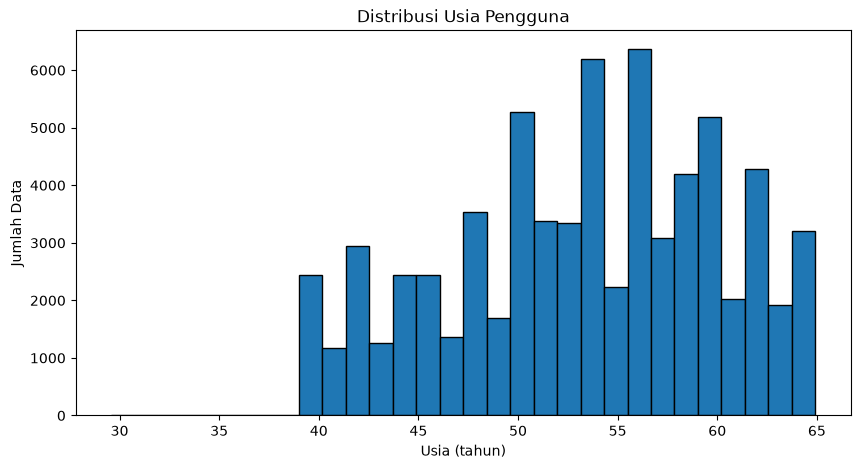

In [23]:
import matplotlib.pyplot as plt

# Membuat histogram distribusi usia
plt.figure(figsize=(10, 5))

plt.hist(age_years, bins=30, edgecolor="black")

plt.title("Distribusi Usia Pengguna")
plt.xlabel("Usia (tahun)")
plt.ylabel("Jumlah Data")

plt.show()